Hidden States:
[[ 0.05840686  0.01650603  0.02204161]
 [ 0.08931158 -0.02892273 -0.05559044]
 [ 0.08103081  0.07238441  0.01109309]
 [ 0.11180732 -0.06626876 -0.03045146]
 [ 0.10230231  0.11481536 -0.01191443]]


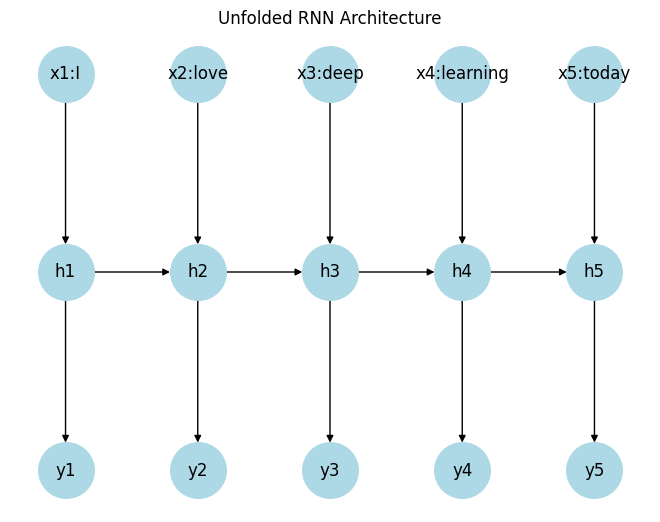

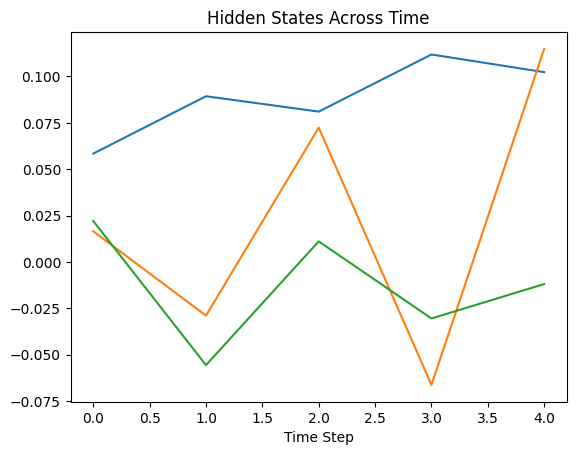

In [4]:

import numpy as np
import tensorflow as tf
import networkx as nx
import matplotlib.pyplot as plt

words = ["I", "love", "deep", "learning", "today"]
ids = np.array([[1, 2, 3, 4, 5]])

inp = tf.keras.Input((5,))
emb = tf.keras.layers.Embedding(6, 4)(inp)

rnn = tf.keras.layers.SimpleRNN(
    3, return_sequences=True, return_state=True)

seq, state = rnn(emb)

model = tf.keras.Model(inp, [seq, state])
states, final_state = model.predict(ids, verbose=0)

print("Hidden States:")
print(states[0])

G = nx.DiGraph()
pos = {}

for i, word in enumerate(words, 1):
    G.add_edge(f"x{i}:{word}", f"h{i}", label="W_xh")
    G.add_node(f"h{i}")

    if i > 1:
        G.add_edge(f"h{i-1}", f"h{i}", label="W_hh")

    G.add_edge(f"h{i}", f"y{i}", label="W_hy")

    pos[f"x{i}:{word}"] = (i, 2)
    pos[f"h{i}"] = (i, 1)
    pos[f"y{i}"] = (i, 0)

nx.draw(G, pos, with_labels=True,
        node_color="lightblue",
        node_size=1600)

plt.title("Unfolded RNN Architecture")
plt.show()

plt.plot(states[0])
plt.title("Hidden States Across Time")
plt.xlabel("Time Step")
plt.show()
